# Ensemble learning

By: Sherif Abdulkader Tawfik Abbas
[https://sheriftawfikabbas.github.io/](https://sheriftawfikabbas.github.io/)

Topics we will cover:
- Why combining models works
- The three big ensemble strategies: voting, bagging, boosting
- Hard vs soft voting on a tabular problem (breast-cancer diagnosis)
- Random Forest as the canonical bagging method
- The same voting idea applied to an ensemble of CNNs (cell images)

## Why ensembles?

A single model makes mistakes. But different models tend to make *different*
mistakes — and when individual errors are at least partially independent, they
cancel out when we combine the models. This is variance reduction, the same
reason averaging repeated measurements is more reliable than any single one.

The three main strategies, summarised on
[Wikipedia](https://en.wikipedia.org/wiki/Ensemble_learning):

- **Voting**: train several models, then combine their predictions —
  majority rule for classes, or averaged probabilities.
- **Bagging** (*bootstrap aggregating*): train each member on a **bootstrap
  resample** of the training data (a random sample drawn *with replacement*).
  The resampling is what decorrelates the members' errors. Random Forest is
  bagging plus random feature subsets.
- **Boosting**: train models **sequentially**, each one focusing on the
  examples its predecessors got wrong (XGBoost, used in our case studies, is
  the industrial-strength version).

For **voting**, two flavours:

- **Hard voting**: each model casts one class vote; the majority wins.
- **Soft voting**: each model outputs class probabilities; we average them
  (optionally weighted) and take the argmax. Soft voting is usually better
  when the members are well-calibrated: a confident model contributes more
  than a hesitant one.

In this class we will vote twice: once over sklearn models on the
breast-cancer dataset from Class02's lab, and once over a small ensemble of
CNNs on cell microscopy images — Case Study 05 develops the image side in
full.

## Part 1 — Voting over sklearn models

We revisit the breast-cancer dataset and apply the exact cleaning recipe
developed in the lab: coerce junk tokens, median-impute `NaN`s, drop rows
with sentinel zeros.

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv('../Class02_DataEngineering/breast_cancer_data.csv', index_col='id')
feature_cols = [c for c in df.columns if c != 'diagnosis']

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
for col in feature_cols:
    df[col] = df[col].fillna(df[col].median())
df = df.loc[~(df[feature_cols] == 0).any(axis=1)]
print('clean shape:', df.shape)

X = df[feature_cols].values
y = (df['diagnosis'] == 'M').astype(int).values   # 1 = malignant

clean shape: (556, 31)


### Train/test split, done properly

`stratify=y` keeps the malignant/benign ratio equal in both sets — with a
37/63 class balance, an unlucky unstratified split can leave the test set
noticeably skewed.

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

### The ensemble members

Three deliberately *different* learners, so their errors don't coincide: a
linear model, a tree, and a distance-based model. Note the pipelines that
standardise features first — k-nearest neighbours and logistic regression are
sensitive to feature scale (one column like `area_mean` reaching 2500 would
otherwise dominate every distance and gradient), while trees don't care.

In [3]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

members = {
    'logistic regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, random_state=42)),
    'decision tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'kNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
}

In [4]:
# Fit the members and score them individually
rows = {}
for name, clf in members.items():
    clf.fit(X_train, y_train)
    rows[name] = clf

hard = VotingClassifier(list(members.items()), voting='hard').fit(X_train, y_train)
soft = VotingClassifier(list(members.items()), voting='soft').fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)

models = {**rows, 'hard voting': hard, 'soft voting': soft, 'random forest': rf}
report = pd.DataFrame(
    {name: {'accuracy': accuracy_score(y_test, m.predict(X_test)),
            'f1': f1_score(y_test, m.predict(X_test))}
     for name, m in models.items()}).T
print(report.round(3).sort_values('f1', ascending=False).to_string())

                     accuracy     f1
hard voting             0.982  0.976
soft voting             0.973  0.965
logistic regression     0.973  0.964
kNN (k=5)               0.955  0.938
random forest           0.946  0.929
decision tree           0.938  0.916


Read the result: the voting ensembles sit at (or very near) the top.

- **Hard voting** needs the majority to be right and can underperform a strong
  member when two weak members gang up wrong.
- **Soft voting** weighs confidence, so it usually matches or beats hard voting —
  though here it ties its best member: when members agree almost everywhere,
  averaging probabilities changes almost nothing. Voting's advantage grows
  with member **disagreement** (decorrelated errors), not member count.
- **Random forest** is *bagging*, not voting: each of its 300 trees saw a
  different bootstrap sample and random feature subsets, which decorrelates
  their errors far more than architecture choice alone.

Exact numbers wiggle a little with library versions, but the pattern is
stable: combining diverse, reasonable models is a low-effort, high-reliability
way to match or beat any of them alone.

## Part 2 — Voting over CNNs (image classification)

Same idea, deep-learning flavour: three CNNs of different widths vote on
whether a blood-cell image shows malaria parasites. Dataset: the NIH malaria
cell images (`Data/cell_images`,
[dataset page](https://www.tensorflow.org/datasets/catalog/malaria)).

### Task 1: Load the cell image data

File names are collected with `glob`, turned into a two-column DataFrame
(path, label), shuffled, and truncated to 2000 images to keep training time
modest. We check the class balance stays close to 50/50.

In [5]:
import glob
import os
import statistics

import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(42)   # reproducible-ish runs

infected = '../../Data/cell_images/Parasitized'
healthy = '../../Data/cell_images/Uninfected'

infected_files = sorted(glob.glob(infected + '/*.png'))
healthy_files = sorted(glob.glob(healthy + '/*.png'))
print(len(infected_files), 'parasitised,', len(healthy_files), 'uninfected images found')

files_df = pd.DataFrame({
    'img': infected_files + healthy_files,
    'malaria': [1] * len(infected_files) + [0] * len(healthy_files)
})
files_df = files_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Use a 2000-image subset to keep CPU training time reasonable; the full
# dataset is ~27,500 images. See Case Study 05 for the deeper evaluation.
files_df = files_df.iloc[0:2000, :]
files_df['malaria'].value_counts()

I0000 00:00:1792721816.492659 2016116 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792721816.539510 2016116 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792721818.098074 2016116 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


13779 parasitised, 13779 uninfected images found


malaria
1    1030
0     970
Name: count, dtype: int64

### Task 2: Images to arrays, and a three-way split

The `get_data` helper reads each PNG, converts OpenCV's BGR channel order to
the RGB order that matplotlib (and most models) expect, and resizes to
50×50. Pixel intensities are divided by 255 to lie in [0, 1].

We then split **three** ways — train / validation / test. Models are fitted
watching the validation set, and the ensemble claims are verified on the
held-out **test** set, which is touched only once at the end. Evaluating the
ensemble on the same data used to tune the members would inflate the result.

In [6]:
img_length, img_width = 50, 50

def get_data(data_files):
    data = []
    skipped = 0
    for path in data_files:
        img = cv2.imread(path)
        if img is None:            # unreadable/corrupt file would crash resize
            skipped += 1
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # cv2 loads BGR
        data.append(cv2.resize(img, (img_length, img_width),
                               interpolation=cv2.INTER_CUBIC))
    if skipped:
        print(f'skipped {skipped} unreadable files')
    return np.asarray(data)

X = get_data(files_df['img'].values) / 255.0
y = files_df['malaria'].values
print('X shape:', X.shape)

X shape: (2000, 50, 50, 3)


train 1200, val 400, test 400


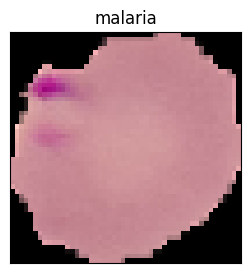

In [7]:
from sklearn.model_selection import train_test_split

# 60% train, 20% validation, 20% test — stratified throughout
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
print(f'train {len(X_train)}, val {len(X_val)}, test {len(X_test)}')

plt.figure(figsize=(3, 3))
plt.imshow(X_train[0])
plt.title('malaria' if y_train[0] else 'healthy')
plt.xticks([]); plt.yticks([])
plt.savefig('cell_sample.png', bbox_inches='tight')
plt.show()

### Task 3: A small CNN

Architecture (each conv layer uses 3×3 kernels and ReLU, followed by 2×2 max
pooling):

- 16 filters → 16 filters → 32 filters
- flatten → dense(32, ReLU) → dropout(0.5) → dense(1, sigmoid)

Why **convolutions** for images? A dense layer treats a 50×50×3 image as
7,500 unrelated inputs; a convolution slides a small filter over the image,
so the same detector (edge, texture, parasite shape) is reused at every
location — *translation invariance* plus far fewer weights. The sigmoid
output is the probability of the positive class, so the matching loss is
`binary_crossentropy`.

In [8]:
from tensorflow.keras.layers import (Conv2D, Dense, Dropout, Flatten,
                                     MaxPooling2D)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

def build_model(width=1.0):
    '''The small CNN above, with layer widths scaled by `width`.'''
    w = lambda n: max(4, int(n * width))
    model = Sequential([
        Conv2D(w(16), (3, 3), activation='relu',
               input_shape=(img_length, img_width, 3)),
        MaxPooling2D(2, 2),
        Conv2D(w(16), (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Conv2D(w(32), (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(w(32), activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid'),   # single probability output
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_model()
model.summary()

/home/abshe/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,857 (93.19 KB)

 Trainable params: 23,857 (93.19 KB)

 Non-trainable params: 0 (0.00 B)

### Task 4: Train and evaluate

Twenty epochs of fitting. Two definitions to keep straight while reading the
report below:

- **Accuracy**: the *fraction of correct predictions*
  `(TP + TN) / (TP + TN + FP + FN)`.
- **Precision** `TP / (TP + FP)`: of the images we called positive, how many
  really are.
- **Recall** `TP / (TP + FN)`: of the truly positive images, how many we found.
- **F1**: the **harmonic mean** of precision and recall,
  `2·P·R / (P + R)`. Harmonic, not arithmetic: the F1 is near zero whenever
  *either* side is near zero, so it punishes lopsided models. In a medical
  screen, recall is what catches missed cases — never optimise accuracy
  alone.

In [9]:
history = model.fit(X_train, y_train, batch_size=64, epochs=20, shuffle=True,
                    validation_data=(X_val, y_val), verbose=0)

base CNN       | accuracy 0.887 | precision 0.935 | recall 0.840 | f1 0.885
              precision    recall  f1-score   support

     healthy       0.85      0.94      0.89       194
     malaria       0.94      0.84      0.88       206

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.89       400
weighted avg       0.89      0.89      0.89       400



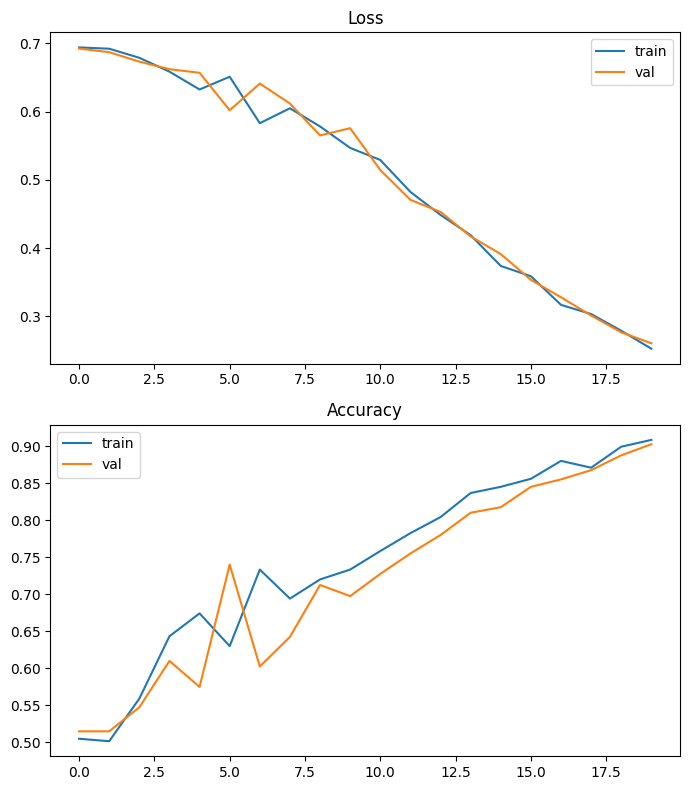

In [10]:
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             precision_score, recall_score)

def evaluate(m, X, y, title=''):
    proba = m.predict(X, verbose=0).ravel()
    y_pred = (proba > 0.5).astype(int)
    print(title, f"accuracy {accuracy_score(y, y_pred):.3f} | "
                 f"precision {precision_score(y, y_pred):.3f} | "
                 f"recall {recall_score(y, y_pred):.3f} | "
                 f"f1 {f1_score(y, y_pred):.3f}")
    return proba, y_pred

proba_base, pred_base = evaluate(model, X_test, y_test, 'base CNN       |')
print(classification_report(y_test, pred_base,
                            target_names=['healthy', 'malaria']))

fig, axes = plt.subplots(2, 1, figsize=(7, 8))
axes[0].set_title('Loss')
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].legend()
axes[1].set_title('Accuracy')
axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='val')
axes[1].legend()
fig.tight_layout()
plt.savefig('accuracy_loss.png', bbox_inches='tight')
plt.show()

The validation curves plateau well before epoch 20 — evidence the model has
converged, and that the last epochs mostly add overfitting risk.

### Task 5: The ensemble

Now build two **larger** variants (the width formula below doubles and
triples the filter counts), fit all three on the *same* training data, and
vote. Two caveats to keep in mind:

1. Because all members see the *same* training set, their errors are only
   decorrelated by different architectures and random initialisation —
   this is a simplified voting scheme. Genuine **bagging** would resample the
   training data per member; with deep nets that is expensive, so the weight
   space's own diversity often substitutes.
2. With **three members on two classes, hard voting can never tie**, so
   `statistics.mode` is safe here. (With an even number of members, ties
   need an explicit rule.)

In [11]:
models = {'width 1x': model,
          'width 2x': build_model(2.0),
          'width 3x': build_model(3.0)}

for name, m in models.items():
    if name != 'width 1x':   # base model already trained above
        m.fit(X_train, y_train, batch_size=64, epochs=20, shuffle=True,
              validation_data=(X_val, y_val), verbose=0)

/home/abshe/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
probas, preds = {}, {}
for name, m in models.items():
    probas[name], preds[name] = evaluate(m, X_test, y_test, f'{name:10s} |')

# Soft voting: average the predicted probabilities, threshold at 0.5
soft_proba = np.mean([probas[n] for n in models], axis=0)
soft_pred = (soft_proba > 0.5).astype(int)

# Hard voting: majority class among the members
hard_pred = np.array([
    statistics.mode([preds[n][i] for n in models]) for i in range(len(y_test))])

print('ENSEMBLE    | soft accuracy {:.3f} f1 {:.3f}'.format(
    accuracy_score(y_test, soft_pred), f1_score(y_test, soft_pred)))
print('ENSEMBLE    | hard accuracy {:.3f} f1 {:.3f}'.format(
    accuracy_score(y_test, hard_pred), f1_score(y_test, hard_pred)))

width 1x   | accuracy 0.887 | precision 0.935 | recall 0.840 | f1 0.885


width 2x   | accuracy 0.915 | precision 0.953 | recall 0.879 | f1 0.914


width 3x   | accuracy 0.925 | precision 0.958 | recall 0.893 | f1 0.925
ENSEMBLE    | soft accuracy 0.920 f1 0.920
ENSEMBLE    | hard accuracy 0.917 f1 0.917


Compare each member individually against the ensemble. With only three
members trained on identical data, the vote tracks the best member closely
and can sit a hair below it — a member that is *lucky* on this particular
test set wins alone. The ensemble's real selling point shows up across
repeated runs: a single unlucky model can drop a couple of points, but a vote
rarely collapses, because that requires several members to be unlucky **in
the same way**. To widen the ensemble's advantage, decorrelate the members:
resample the training data per member (bagging proper), vary the seeds,
input crops or architectures more aggressively, or add more than three members.

Case Study 05 takes over from here with patient-grouped splits, ROC curves,
confusion matrices and error analysis on the image problem; Case Studies
01/04 apply XGBoost-style **boosting** to forecasting.